# Does BCA's weighting help when the held-out tries come from different conditions than deployment?

## Bottom line (written after the run)

- **Yes. BCA's weights earn their keep when the held-out tries come from a different mix of conditions than deployment.** All six claims survived.
- **Ignoring the shift breaks the promise.** When harm sits in the conditions deployment meets more often than the log, the unweighted tail gate deviated in up to 90% of seeds in unsafe worlds. The unweighted mean gate deviated in up to 94% of seeds in harmful worlds.
- **With weights, both BCA gates kept their promise in every world.** The weighted tail gate, as built in `calibration/wbcp.py`, deviated in at most 4.3% of seeds in any unsafe world. The weighted mean gate deviated in at most 4.4% of seeds in any harmful world. Weighted split conformal reached 39%, because its guarantee holds only on average over data sets.
- **Weights use the evidence better than the simple valid alternatives.** In safe worlds with a shift, the weighted tail gate said yes in 34% of seeds, against 19% for rejection sampling and 0% for per-condition bounds.
- **At equal harm, the weighted mean gate earned the most, but narrowly:** 0.0975 per decision, against 0.0923 for a tuned weighted split conformal. That rival's safety came from tuning to these worlds, not from a promise.
- **The price is evidence.** Under the strong shift, the weighted tail gate could not say yes with fewer than about 83 tries, against 29 with no shift. Ignoring the shift earned more (0.111 against 0.084), but only by breaking the promise in 17 unsafe worlds. Held to the same safety level, it earned less (0.054).
- **A version with a proof gives up little at equal harm.** Give the worst case the largest weight instead of the average one, and the July 2026 proof appears to cover the gate. It earned less at the stated level (0.080 against 0.098 per decision), but nearly as much at equal harm (0.0954 against 0.0975). This comparison was added after the run, as information only.
- **The weights here are known exactly.** Real weights must be estimated, and errors in them were not tested.

The details are in the last sections: *What we found*, *What this means for BCA* and *What this does not show*.

**How to run:** open this notebook in the repository's `.venv` and choose Run All. It needs Python 3, NumPy and Matplotlib, and takes three to five minutes. Nothing is downloaded. One check imports the repository's `calibration/wbcp.py`, to confirm that this notebook computes weighted BCA the same way; it writes no cache files.

**Why this notebook exists.** With equal weights, BCA is a textbook test ([bca_channel_toy.ipynb](bca_channel_toy.ipynb)). Its one part that is not textbook is its **weights**. Production BCA can reweight held-out tries so that they speak for the conditions the policy will actually meet. That matters when the tries come from a different mix of conditions than deployment. This notebook tests whether the weights earn their keep.

Everything here is a toy, run on toy seeds only. The kill rules (the results that would shelve each claim) were written before the first run and fingerprinted in the cell that defines them.

## The setup

- A policy wants to **deviate**: take a risky action (think full throttle) instead of a well-logged **fallback**. It makes one decision for a whole region of states: deviate everywhere in the region, or fall back everywhere.
- The region has five **conditions**, from mild (0) to harsh (4). The log's held-out tries of the deviation came mostly from mild conditions. Deployment may meet harsh conditions more often. The difference between the two mixes is the **shift**.
- Each try's **gain** over the fallback is usually small and positive (about 0.5), but sometimes it is a **disaster** (−4). How often disasters happen depends on the condition.
- A **gate** reads the held-out tries and decides. Two kinds of promise are tested:
  - **Tail promise:** deviate only if at most 10% of outcomes at deployment fall below the fallback, with 95% confidence.
  - **Mean promise:** deviate only if the average gain at deployment is above 0, with 95% confidence.
- **Weights.** A try gets weight = (its condition's share at deployment) ÷ (its condition's share in the log). A try from a condition that deployment meets often, but the log rarely saw, counts for more. Here the weights are known exactly.

## Words used

- **Unsafe world:** more than 10% of outcomes at deployment fall below the fallback. **Harmful world:** the average gain at deployment is below 0.
- **Deviation rate:** the share of seeds in which a gate deviates. In an unsafe or harmful world, it is how often the gate breaks its promise; a gate that keeps its promise stays at or below 5%.
- **Effective number of tries:** how many equally weighted tries the weighted ones are worth: (sum of weights)² ÷ (sum of squared weights). A stronger shift makes it smaller.
- **Gain:** the true average gain at deployment if the gate deviates, and 0 if it falls back. **Pooled gain** averages over all worlds.

## The worlds

| Factor | Settings |
|---|---|
| Where harm sits | everywhere alike; in harsh conditions; in mild conditions |
| Disaster chance at deployment (the **rung**) | 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20 |
| Shift | none; moderate; strong |
| Held-out tries | 30, 60, 120, 240 |

That makes 288 worlds, each run on 800 seeds.

- **The rung fixes the truth at deployment.** Rungs 0.10 and above are unsafe; rungs 0.12 and above are harmful. At 0.10 the deviation is unsafe but still good on average.
- **Where harm sits, and the shift, change only what the log shows.** When harm sits in harsh conditions and deployment meets them more often, the log makes the deviation look safer than it is. When harm sits in mild conditions, the log makes it look worse.

| Condition | 0 (mild) | 1 | 2 | 3 | 4 (harsh) |
|---|---|---|---|---|---|
| Share among the log's tries | 35% | 25% | 20% | 12% | 8% |
| Share at deployment, moderate shift | 15% | 20% | 25% | 20% | 20% |
| Share at deployment, strong shift | 5% | 10% | 15% | 30% | 40% |

All worlds share the same random numbers, so differences between worlds come from the worlds, not from luck.

## The gates

| Gate | Deviates when | Promise |
|---|---|---|
| never deviate, always deviate | never; always | references |
| BCA tail, unweighted | BCA with equal weights (in exact form) is 95% sure that at least 90% of tries beat the fallback | tail, but for the log's mix |
| **BCA tail, weighted** | the same, with BCA's weights and its extra worst-case weight, as built in `calibration/wbcp.py` (1,000 draws) | tail, at deployment: claim 2 tests it |
| weighted split conformal | the weighted 10% cutoff of the tries beats the fallback (Tibshirani and others, 2019) | tail, at deployment, only on average over data sets |
| rejection-sampled exact | each try is kept with chance weight ÷ largest weight, then the exact test runs on the kept tries (Park and others, 2022) | tail, at deployment |
| stratified exact | an exact bound per condition (at 1% each), combined with the deployment mix | tail, at deployment |
| BCA mean, unweighted | BCA's mean gate on all tries, with floor −4 (10,000 draws) | mean, but for the log's mix |
| **BCA mean, weighted** | the same, with weights on the tries and the average deployment weight on the extra floor weight | mean, at deployment: claim 5 tests it |
| rejection-sampled BCA mean | BCA's mean gate on the kept tries | mean, at deployment |
| weighted t-test | the weighted average, minus a t-test margin with the usual weighted standard error, is above 0 | mean, roughly, if outcomes are bell-shaped |
| weighted average | the weighted average gain is above 0 | none |
| plain average | the plain average gain is above 0 | none |
| oracle | the deviation is truly good on average at deployment | scoring reference |

The two bold gates are under test. Rejection sampling and the stratified bound are the simple ways to keep a valid promise under shift, and both throw evidence away. No proof covers the weighted mean gate; it is the natural weighted version of [the mean gate](bca_mean_gate_toy.ipynb).

In [1]:
import math, os, sys, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 43
N_SEEDS = 800
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 400), np.arange(400, 800)
SHIFTS = ("none", "moderate", "strong")
LOG_PCT = np.array([35, 25, 20, 12, 8])                          # conditions 0 (mild) to 4 (harsh), in percent
DEPLOY_PCT = {"none": LOG_PCT, "moderate": np.array([15, 20, 25, 20, 20]), "strong": np.array([5, 10, 15, 30, 40])}
PROFILES = ("harm everywhere alike", "harm in harsh conditions", "harm in mild conditions")
STEEPNESS = 0.6                                                  # how sharply harm rises or falls across conditions
RUNGS = (0.0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20)          # disaster chance at deployment
SIZES = (30, 60, 120, 240)                                       # held-out tries the gate reads
N_MAX = max(SIZES)
CENTER, SPREAD, LO, HI = 0.5, 0.2, -1.0, 2.0                     # usual gain: clip(0.5 + 0.2 Z, -1, 2)
DISASTER = FLOOR = -4.0                                          # a disaster's gain, also the worst possible gain
TAIL, CONFIDENCE, DELTA = 0.10, 0.95, 0.05
TAIL_DRAWS, MEAN_DRAWS = 1000, 10_000                            # 1,000 as built for the tail gate
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05)              # knob grids for claim 6
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001)
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.75, 1.0)

LOG_MIX = LOG_PCT / 100
DEPLOY_MIX = {s: DEPLOY_PCT[s] / 100 for s in SHIFTS}
STRATA_LEVEL = DELTA / LOG_MIX.size
WEIGHT = np.array([DEPLOY_PCT[s] / LOG_PCT for s in SHIFTS])     # (shift, condition): deployment share / log share
WBAR = np.array([float(sum(Fraction(int(d) ** 2, int(l)) for d, l in zip(DEPLOY_PCT[s], LOG_PCT)) / 100)
                 for s in SHIFTS])                               # average weight at deployment (BCA's test mass)
WMAX = WEIGHT.max(axis=1)
assert all(DEPLOY_PCT[s].sum() == 100 for s in SHIFTS) and TAIL in TAIL_SHARES and DELTA in LEVELS

## How much evidence each tail gate needs

Shift costs every valid gate evidence; the question is how much. The cell below shows how many held-out tries each tail gate needs before it can say yes at all, even when every try beats the fallback. (Unweighted BCA needs 29 in every case, but under shift it answers for the wrong mix.)

In [2]:
def tries_needed_weighted(si):
    """About how many tries weighted BCA's tail gate needs to say yes when every try beats the fallback."""
    c = TAIL / ((1 - TAIL) * WBAR[si])
    return math.ceil(math.log(1 / (1 - CONFIDENCE)) / (LOG_MIX @ np.log1p(c * WEIGHT[si])))

def tries_needed_stratified(si):
    """About how many tries the stratified exact gate needs, with condition counts at their expected values."""
    for n in range(1, 5000):
        bound = DEPLOY_MIX[SHIFTS[si]] @ (1 - STRATA_LEVEL ** (1 / (n * LOG_MIX)))
        if bound <= TAIL:
            return n
    return math.inf

print("shift      effective tries   tries kept by       tries needed to say yes at all (about)")
print("           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact")
for si, shift in enumerate(SHIFTS):
    print(f"{shift:10}{1 / WBAR[si]:>11.2f}{1 / WMAX[si]:>17.2f}{tries_needed_weighted(si):>22d}"
          f"{math.ceil(29 * WMAX[si]):>20d}{tries_needed_stratified(si):>23d}")

shift      effective tries   tries kept by       tries needed to say yes at all (about)
           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact
none             1.00             1.00                    29                  29                    216
moderate         0.73             0.40                    39                  73                    287
strong           0.34             0.20                    83                 145                    382


## World and gate code

In [3]:
def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def phi(x):
    return math.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo, hi):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

PROFILE_SHAPE = {"harm everywhere alike": np.ones(LOG_MIX.size),
                 "harm in harsh conditions": np.exp(STEEPNESS * (np.arange(LOG_MIX.size) - 2)),
                 "harm in mild conditions": np.exp(-STEEPNESS * (np.arange(LOG_MIX.size) - 2))}

def disaster_chances(profile, rung, shift):
    """Disaster chance in each condition, scaled so that deployment's overall chance is the rung."""
    shape = PROFILE_SHAPE[profile]
    return rung * shape / (DEPLOY_MIX[shift] @ shape)

P_K = np.array([[[disaster_chances(p, r, s) for s in SHIFTS] for r in RUNGS] for p in PROFILES])  # (profile, rung, shift, condition)
USUAL_MEAN = clipped_mean(CENTER, SPREAD, LO, HI)
USUAL_BELOW = Phi(-CENTER / SPREAD)                             # chance that a usual gain is below 0
RUNG = np.array(RUNGS)
MU = (1 - RUNG) * USUAL_MEAN + RUNG * DISASTER                  # true average gain at deployment, by rung
BAD = RUNG + (1 - RUNG) * USUAL_BELOW                           # true share of outcomes below the fallback at deployment
UNSAFE, HARMFUL = BAD > TAIL, MU < 0
WORLD = (len(PROFILES), len(RUNGS), len(SHIFTS), len(SIZES))

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's equal-weight tail gate in exact form: the most tries that may fall below the fallback, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

LOGFACT = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, N_MAX + 1)))])

def cp_upper(b, n, level):
    """Clopper-Pearson upper bounds for arrays of (bad, tries): the largest p with P(Binomial(n, p) <= b) >= level."""
    b, n = np.asarray(b, dtype=int), np.asarray(n, dtype=int)
    out = np.ones(b.shape)
    todo = b < n
    bb, nn = b[todo], n[todo]
    x = np.arange(N_MAX + 1)[None, :]
    inside = x <= bb[:, None]
    logc = LOGFACT[nn][:, None] - LOGFACT[x] - LOGFACT[np.clip(nn[:, None] - x, 0, None)]
    lo, hi = np.zeros(bb.size), np.ones(bb.size)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        logpmf = logc + x * np.log(mid)[:, None] + (nn[:, None] - x) * np.log1p(-mid)[:, None]
        cdf = np.exp(np.where(inside, logpmf, -np.inf)).sum(axis=1)
        up = cdf >= level
        lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
    out[todo] = lo
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * MEAN_DRAWS)

In [4]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A world is one combination of where harm sits (3 profiles), the disaster chance at deployment (the
rung: 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15 or 0.20), how far deployment's mix of conditions differs from the
log's (no, moderate or strong shift) and how many held-out tries the gate reads (30, 60, 120 or 240), so there
are 288 worlds. A world is unsafe when more than 10% of the deviation's outcomes at deployment fall below the
fallback, harmful when its true average gain over the fallback at deployment is below zero, and safe when it is
not unsafe. Shifted worlds have a moderate or strong shift. A gate's deviation rate in a world is the share of
seeds in which it deviates. Unless a claim says otherwise, results use all 800 seeds and each gate's stated
setting. A world's allowance on a 5% rate is 0.05 + 3 * sqrt(0.05 * 0.95 / 800), about 0.073. Pooled gain is
a gate's deviation rate times the true average gain at deployment, averaged over all 288 worlds with equal
weight.

Claim 1. Ignoring the shift breaks BCA's tail promise. Shelved if the unweighted BCA tail gate's deviation rate
is within the allowance in every unsafe world.

Claim 2. With weights, BCA's tail gate as built keeps its promise under shift. Shelved if its deviation rate is
above the allowance in any unsafe world.

Claim 3. BCA's weights use shifted evidence better than the simple valid alternatives. Shelved unless, pooled
over the safe shifted worlds, the weighted BCA tail gate's deviation rate is at least 0.05 above the
rejection-sampled exact test's and at least 0.05 above the stratified exact test's.

Claim 4. Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's. Shelved unless
weighted split conformal's highest deviation rate over the unsafe worlds is at least 0.05 above the weighted BCA
tail gate's highest.

Claim 5. With weights, BCA's mean gate keeps its promise under shift. Shelved if its deviation rate is above the
allowance in any harmful world.

Claim 6. At equal harm, the weighted BCA mean gate earns the most. On seeds 0-399, each tunable gate takes the
setting from its fixed grid with the highest pooled gain among settings whose deviation rate is at most 0.05 in
every harmful world; a gate with no such setting never deviates. Shelved if, on seeds 400-799, any other tuned
gate's pooled gain is at least the tuned weighted BCA mean gate's.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): e32e04d79b52e3a234e2576ef7cddf9c7b667436315b58330fe827b2dafff44e


## Run

For each seed, the cell below draws the log's held-out tries once (their conditions, disaster coins, usual gains, rejection-sampling coins) and BCA's random weightings once, and reuses them in every world. It records what each gate needs to know about the tries.

In [5]:
FIELDS = ("bad", "wgood", "wsum", "wsq", "kept", "kept_bad", "neg_w", "neg_u", "neg_r", "m_w", "se_w", "m_u")
SHIFT_OF = np.broadcast_to(np.arange(len(SHIFTS)), WORLD[:3]).reshape(-1)    # shift of each flattened world

def run_seed(seed):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)            # each try's condition, from the log's mix
    u, v = rng.random((2, N_MAX))                                 # disaster coin; rejection-sampling coin
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))         # BCA's random weights; the last column is the extra one
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))   # (profile, rung, shift, try)
    good = gain >= 0
    w = WEIGHT[:, cond]                                           # (shift, try)
    keep = v < w / WMAX[:, None]
    rec = {f: np.zeros(WORLD) for f in FIELDS}
    rec["cross"] = np.zeros((len(TAIL_SHARES),) + WORLD)
    rec["n_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    rec["b_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    for zi, n in enumerate(SIZES):
        g, ok, kn = gain[..., :n], good[..., :n], keep[:, :n]
        W = w[None, None, :, :n]                                  # broadcast over profile and rung
        flat = lambda a: np.broadcast_to(a, g.shape).reshape(-1, n).T     # (tries, worlds)
        rec["bad"][..., zi] = (~ok).sum(-1)
        rec["wgood"][..., zi] = (W * ok).sum(-1)
        rec["wsum"][..., zi] = W.sum(-1)
        rec["wsq"][..., zi] = (W ** 2).sum(-1)
        rec["kept"][..., zi] = kn.sum(-1)[None, None]
        rec["kept_bad"][..., zi] = (kn[None, None] & ~ok).sum(-1)
        onehot = cond[:n] == np.arange(LOG_MIX.size)[:, None]    # (condition, try)
        rec["n_k"][..., zi, :] = onehot.sum(-1)
        rec["b_k"][..., zi, :] = (~ok[..., None, :] & onehot).sum(-1)
        m_w = (W * g).sum(-1) / W.sum(-1)
        rec["m_w"][..., zi] = m_w
        rec["se_w"][..., zi] = np.sqrt((W ** 2 * (g - m_w[..., None]) ** 2).sum(-1)) / W.sum(-1)
        rec["m_u"][..., zi] = g.mean(-1)
        # Mean gates: count the weighted averages below 0. A weighted average is below 0 exactly when its
        # weighted sum is, because the weights are positive.
        en, extra = e[:, :n], e[:, N_MAX]
        for field, x, extra_mass in (("neg_w", W * g, WBAR[SHIFT_OF] * FLOOR),
                                     ("neg_u", g, np.full(SHIFT_OF.size, FLOOR)),
                                     ("neg_r", kn[None, None] * g, np.full(SHIFT_OF.size, FLOOR))):
            sums = en @ flat(x) + extra[:, None] * extra_mass[None, :]
            rec[field][..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
        # Weighted tail gate as built: a draw crosses at or below 0 when the mass on tries that beat the fallback
        # reaches 1 - share of the total, the extra worst-case weight included.
        et, extra_t = e[:TAIL_DRAWS, :n], e[:TAIL_DRAWS, N_MAX]
        s_good = et @ flat(W * ok)
        s_all = (et @ w[:, :n].T)[:, SHIFT_OF]
        for k, share in enumerate(TAIL_SHARES):
            rhs = (1 - share) * (s_all + extra_t[:, None] * WBAR[SHIFT_OF][None, :])
            rec["cross"][k][..., zi] = (s_good >= rhs).sum(axis=0).reshape(WORLD[:3])
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in records[0]}     # axes: seed, [knob,] profile, rung, shift, size
pairs = np.unique(np.stack([R["b_k"].ravel(), R["n_k"].ravel()]).astype(int), axis=1)
bound = dict(zip(map(tuple, pairs.T), cp_upper(pairs[0], pairs[1], STRATA_LEVEL)))
U = np.vectorize(lambda b, n: bound[(int(b), int(n))])(R["b_k"], R["n_k"])
STRATA_BOUND = (U * np.array([DEPLOY_MIX[s] for s in SHIFTS])[:, None, :]).sum(-1)   # bound on deployment's bad share
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s")

800 seeds in 155 s


In [6]:
TAIL_GATES = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
              "stratified exact"]
LEVEL_GATES = ["BCA mean, unweighted", "BCA mean, weighted", "rejection-sampled BCA mean", "weighted t-test"]
MARGIN_GATES = ["weighted average", "plain average"]
GATES = ["never deviate", "always deviate"] + TAIL_GATES + LEVEL_GATES + MARGIN_GATES + ["oracle"]
SIZE_B = np.array(SIZES)[None, None, None, None, :]
WBAR_B = WBAR[None, None, None, :, None]
NEED = math.ceil(Fraction(str(CONFIDENCE)) * TAIL_DRAWS)

def accept(gate, knob=None):
    """Which (seed, world) cases a gate deviates in, at its stated setting or at knob."""
    share = TAIL if knob is None else knob
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    shape = R["bad"].shape
    if gate == "never deviate":
        return np.zeros(shape, bool)
    if gate == "always deviate":
        return np.ones(shape, bool)
    if gate == "oracle":
        return np.broadcast_to((MU > 0)[None, None, :, None, None], shape).copy()
    if gate == "BCA tail, unweighted":
        return R["bad"] <= np.array([allowed_below(n, share) for n in SIZES])[None, None, None, None, :]
    if gate == "BCA tail, weighted":
        return (R["wgood"] >= (1 - share) * R["wsum"] - 1e-9) & (R["cross"][:, TAIL_SHARES.index(share)] >= NEED)
    if gate == "weighted split conformal":
        return R["wgood"] >= (1 - share) * (R["wsum"] + WBAR_B)
    if gate == "rejection-sampled exact":
        return R["kept_bad"] <= by_count(lambda k: allowed_below(k, share))[R["kept"].astype(int)]
    if gate == "stratified exact":
        return STRATA_BOUND <= share
    if gate == "BCA mean, unweighted":
        return R["neg_u"] <= limit(level)
    if gate == "BCA mean, weighted":
        return R["neg_w"] <= limit(level)
    if gate == "rejection-sampled BCA mean":
        return R["neg_r"] <= limit(level)
    if gate == "weighted t-test":
        tq = np.array([t_upper(level, n - 1) for n in SIZES])[None, None, None, None, :]
        return R["m_w"] - tq * R["se_w"] > 0
    if gate == "weighted average":
        return R["m_w"] > margin
    if gate == "plain average":
        return R["m_u"] > margin
    raise KeyError(gate)

DEC = {g: accept(g) for g in GATES}
ALL = np.arange(N_SEEDS)
SHIFTED = np.broadcast_to((np.arange(len(SHIFTS)) > 0)[None, None, :, None], WORLD)
UNSAFE_W = np.broadcast_to(UNSAFE[None, :, None, None], WORLD)
HARMFUL_W = np.broadcast_to(HARMFUL[None, :, None, None], WORLD)
SAFE_SHIFTED = ~UNSAFE_W & SHIFTED
GAIN_W = np.broadcast_to(MU[None, :, None, None], WORLD)
ALLOW = DELTA + 3 * math.sqrt(DELTA * (1 - DELTA) / N_SEEDS)

def rate(d, seeds=ALL):
    return d[seeds].mean(axis=0)

def pooled_gain(d, seeds=ALL):
    return (rate(d, seeds) * GAIN_W).mean()

ORACLE_GAIN = pooled_gain(DEC["oracle"])

## Results

**How to read the table.** One row per gate at its stated setting, over all 800 seeds.

- **worst unsafe:** the highest deviation rate over the unsafe worlds. A gate that keeps the tail promise stays near or below 5%.
- **safe, shifted:** the deviation rate pooled over safe worlds with a moderate or strong shift. Higher means the gate makes more use of good evidence.
- **worst harmful:** the highest deviation rate over the harmful worlds. A gate that keeps the mean promise stays near or below 5%.
- **gain:** pooled gain per decision. Always falling back scores 0; **of oracle** is the share of the oracle's gain.

The oracle answers the mean question, so it deviates in the unsafe-but-good rung 0.10; its "worst unsafe" of 1.000 is expected.

In [7]:
print(f"{'gate':28}{'worst unsafe':>13}{'safe, shifted':>15}{'worst harmful':>15}{'gain':>8}{'of oracle':>11}")
for g in GATES:
    r = rate(DEC[g])
    print(f"{g:28}{r[UNSAFE_W].max():13.3f}{r[SAFE_SHIFTED].mean():15.3f}{r[HARMFUL_W].max():15.3f}"
          f"{pooled_gain(DEC[g]):8.4f}{pooled_gain(DEC[g]) / ORACLE_GAIN:11.0%}")

gate                         worst unsafe  safe, shifted  worst harmful    gain  of oracle
never deviate                       0.000          0.000          0.000  0.0000         0%
always deviate                      1.000          1.000          1.000  0.0950        55%
BCA tail, unweighted                0.899          0.550          0.736  0.1106        64%
BCA tail, weighted                  0.043          0.336          0.025  0.0838        49%
weighted split conformal            0.388          0.750          0.266  0.1423        83%
rejection-sampled exact             0.036          0.190          0.021  0.0644        37%
stratified exact                    0.000          0.000          0.000  0.0023         1%
BCA mean, unweighted                0.986          0.647          0.936  0.1253        73%
BCA mean, weighted                  0.119          0.415          0.044  0.0982        57%
rejection-sampled BCA mean          0.119          0.261          0.026  0.0789        46%

In [8]:
verdict = lambda alive: "ALIVE" if alive else "SHELVED"
r1 = rate(DEC["BCA tail, unweighted"])[UNSAFE_W]
print(f"Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate {r1.max():.3f}; "
      f"unsafe worlds above the allowance ({ALLOW:.3f}): {(r1 > ALLOW).sum()} -> {verdict((r1 > ALLOW).any())}")
r2 = rate(DEC["BCA tail, weighted"])[UNSAFE_W]
print(f"Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate {r2.max():.3f}; "
      f"above the allowance: {(r2 > ALLOW).sum()} -> {verdict(not (r2 > ALLOW).any())}")
acc = {g: rate(DEC[g])[SAFE_SHIFTED].mean() for g in ("BCA tail, weighted", "rejection-sampled exact", "stratified exact")}
c3 = acc["BCA tail, weighted"] - max(acc["rejection-sampled exact"], acc["stratified exact"]) >= 0.05
print(f"Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds "
      f"{acc['BCA tail, weighted']:.3f}, against rejection-sampled {acc['rejection-sampled exact']:.3f} "
      f"and stratified {acc['stratified exact']:.3f} -> {verdict(c3)}")
w4 = {g: rate(DEC[g])[UNSAFE_W].max() for g in ("weighted split conformal", "BCA tail, weighted")}
c4 = w4["weighted split conformal"] - w4["BCA tail, weighted"] >= 0.05
print(f"Claim 4, a promise for the data in hand: worst unsafe-world rate {w4['weighted split conformal']:.3f} for "
      f"weighted split conformal, against {w4['BCA tail, weighted']:.3f} for weighted BCA -> {verdict(c4)}")
r5 = rate(DEC["BCA mean, weighted"])[HARMFUL_W]
print(f"Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate {r5.max():.3f}; "
      f"above the allowance: {(r5 > ALLOW).sum()} -> {verdict(not (r5 > ALLOW).any())}")

TUNABLE = {g: TAIL_SHARES for g in TAIL_GATES} | {g: LEVELS for g in LEVEL_GATES} | {g: MARGINS for g in MARGIN_GATES}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, rate(d, TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(d, TUNE_SEEDS), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, pooled_gain(d, EVAL_SEEDS), rate(d, EVAL_SEEDS)[HARMFUL_W].max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean, weighted"), key=lambda g: TUNED[g][2])
c6 = TUNED["BCA mean, weighted"][2] > TUNED[best_rival][2]
print(f"Claim 6, at equal harm: tuned weighted BCA mean gate gains {TUNED['BCA mean, weighted'][2]:.4f}; best tuned "
      f"rival {best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c6)}")

Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate 0.899; unsafe worlds above the allowance (0.073): 17 -> ALIVE
Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate 0.043; above the allowance: 0 -> ALIVE
Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds 0.336, against rejection-sampled 0.190 and stratified 0.000 -> ALIVE
Claim 4, a promise for the data in hand: worst unsafe-world rate 0.388 for weighted split conformal, against 0.043 for weighted BCA -> ALIVE
Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate 0.044; above the allowance: 0 -> ALIVE
Claim 6, at equal harm: tuned weighted BCA mean gate gains 0.0975; best tuned rival weighted split conformal gains 0.0923 -> ALIVE


### Equal harm: each gate tuned to the same safety level

Each gate has one knob: the share for the tail gates, the confidence level for the mean gates and the t-test, and a margin for the averages. The chart shows every setting on seeds 0–399: how often the gate deviates in its worst harmful world (left–right), and its pooled gain (up–down). The table takes each gate's best setting that stays at or below 5% in every harmful world, and scores it on the fresh seeds 400–799.

gate                         chosen knob  gain, 0-399  gain, 400-799  worst harmful, 400-799
BCA mean, weighted                  0.05       0.0988         0.0975                   0.052
weighted split conformal            0.05       0.0923         0.0923                   0.048
BCA tail, weighted                   0.1       0.0838         0.0838                   0.030
rejection-sampled BCA mean          0.05       0.0791         0.0788                   0.025
rejection-sampled exact              0.1       0.0642         0.0646                   0.018
BCA tail, unweighted                0.05       0.0517         0.0536                   0.020
stratified exact                     0.2       0.0351         0.0358                   0.005
BCA mean, unweighted                none       0.0000         0.0000                   0.000
weighted t-test                     none       0.0000         0.0000                   0.000
weighted average                    0.75       0.0000         0.0000  

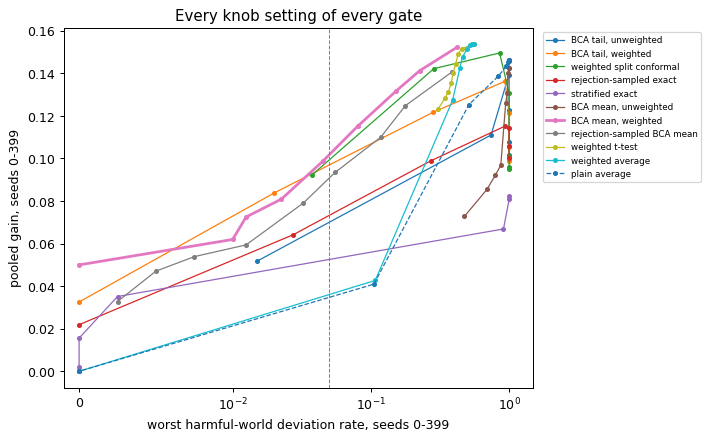

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    ax.plot([p[1] for p in points], [p[2] for p in points], marker="o", ms=3,
            lw=2.2 if g == "BCA mean, weighted" else 1, color=f"C{i % 10}", ls="-" if i < 10 else "--", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst harmful-world deviation rate, seeds 0-399")
ax.set_ylabel("pooled gain, seeds 0-399")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':28}{'chosen knob':>12}{'gain, 0-399':>13}{'gain, 400-799':>15}{'worst harmful, 400-799':>24}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:28}{'none' if k is None else str(k):>12}{tune_gain:13.4f}{eval_gain:15.4f}{eval_harm:24.3f}")

### Where the differences come from

**How to read the breakdowns.** The same measures, split by shift and by number of tries. The figure shows each gate's deviation rate along the rungs, under strong shift with 120 tries. Rungs to the right of the first dashed line are unsafe, and to the right of the second are harmful.

In [10]:
key = TAIL_GATES + LEVEL_GATES + MARGIN_GATES
def by(fn, label, columns, fmt):
    print(label)
    print(f"{'gate':28}" + "".join(f"{c:>12}" for c in columns))
    for g in key:
        print(f"{g:28}" + "".join(f"{v:{fmt}}" for v in fn(rate(DEC[g]))))
    print()

by(lambda r: [r[:, :, s][UNSAFE_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst unsafe-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][~UNSAFE_W[:, :, s]].mean() for s in range(len(SHIFTS))],
   "Deviation rate pooled over safe worlds, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][HARMFUL_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst harmful-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [(r * GAIN_W)[:, :, s].mean() for s in range(len(SHIFTS))],
   "Pooled gain, by shift", SHIFTS, "12.4f")
by(lambda r: [r[..., z][SAFE_SHIFTED[..., z]].mean() for z in range(len(SIZES))],
   "Deviation rate pooled over safe shifted worlds, by number of tries", SIZES, "12.3f")
by(lambda r: [(r * GAIN_W)[..., z].mean() for z in range(len(SIZES))],
   "Pooled gain, by number of tries", SIZES, "12.4f")
by(lambda r: [(r * GAIN_W)[p, :, 2].mean() for p in range(len(PROFILES))],
   "Pooled gain under strong shift, by where harm sits", ("alike", "harsh", "mild"), "12.4f")

ess = R["wsum"] ** 2 / R["wsq"]
print("Effective number of tries, and tries kept by rejection sampling (averages over seeds)")
print(f"{'shift':10}" + "".join(f"{f'{n} tries':>18}" for n in SIZES))
for s, shift in enumerate(SHIFTS):
    print(f"{shift:10}" + "".join(f"{ess[:, 0, 0, s, z].mean():9.1f} /{R['kept'][:, 0, 0, s, z].mean():6.1f}  "
                                  for z in range(len(SIZES))))

Worst unsafe-world deviation rate, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.036       0.454       0.899
BCA tail, weighted                 0.031       0.043       0.037
weighted split conformal           0.388       0.369       0.355
rejection-sampled exact            0.036       0.026       0.025
stratified exact                   0.000       0.000       0.000
BCA mean, unweighted               0.119       0.746       0.986
BCA mean, weighted                 0.119       0.098       0.094
rejection-sampled BCA mean         0.119       0.079       0.044
weighted t-test                    0.179       0.240       0.440
weighted average                   0.730       0.714       0.689
plain average                      0.730       0.996       1.000

Deviation rate pooled over safe worlds, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.539       0.551       0.

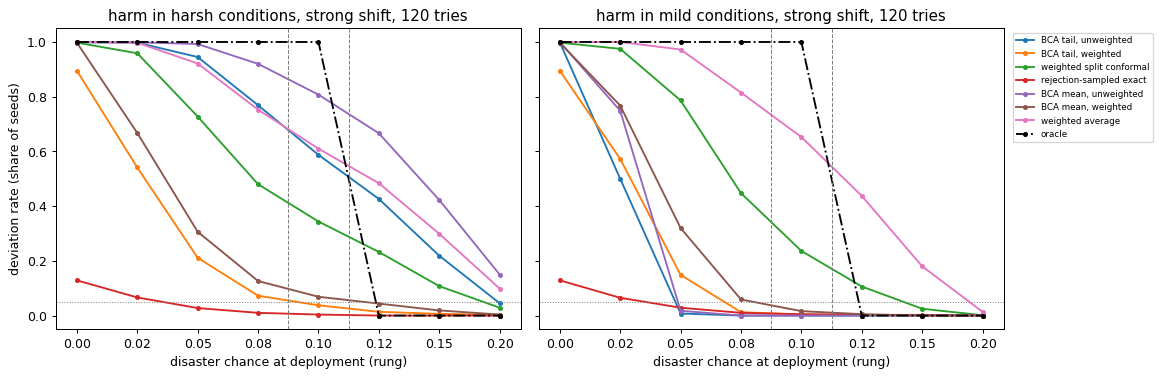

In [11]:
show = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
        "BCA mean, unweighted", "BCA mean, weighted", "weighted average", "oracle"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, p in zip(axes, (1, 2)):
    for i, g in enumerate(show):
        ax.plot(range(len(RUNGS)), rate(DEC[g])[p, :, 2, SIZES.index(120)], marker="o", ms=3,
                color="k" if g == "oracle" else f"C{i}", ls="-." if g == "oracle" else "-", label=g)
    ax.axvline(int(np.argmax(UNSAFE)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axvline(int(np.argmax(HARMFUL)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axhline(DELTA, color="grey", ls=":", lw=0.8)
    ax.set_xticks(range(len(RUNGS))); ax.set_xticklabels([f"{r:.2f}" for r in RUNGS])
    ax.set_xlabel("disaster chance at deployment (rung)")
    ax.set_title(f"{PROFILES[p]}, strong shift, 120 tries")
axes[0].set_ylabel("deviation rate (share of seeds)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

## Checks

These checks confirm that the toy works as described; any failure stops the notebook.

In [12]:
# 1. Each world's disaster chances are valid and add up to its rung at deployment; the exact truths match simulation.
for pi in range(len(PROFILES)):
    for ri, rung in enumerate(RUNGS):
        for si, shift in enumerate(SHIFTS):
            pk = P_K[pi, ri, si]
            assert np.all((pk >= 0) & (pk <= 1)) and abs(DEPLOY_MIX[shift] @ pk - rung) < 1e-12
rng = np.random.default_rng([ROOT_SEED, 999])
cond = rng.choice(LOG_MIX.size, 1_000_000, p=DEPLOY_MIX["strong"])
gains = np.where(rng.random(cond.size) < P_K[1, 5, 2][cond], DISASTER,
                 np.clip(CENTER + SPREAD * rng.standard_normal(cond.size), LO, HI))
assert abs(gains.mean() - MU[5]) < 5 * gains.std() / 1000 and abs((gains < 0).mean() - BAD[5]) < 0.002
# 2. The weighted tail gate here decides exactly as production BCA (calibration/wbcp.py) does.
sys.dont_write_bytecode = True
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
try:
    from calibration.wbcp import calibrate
except ImportError:
    calibrate = None
    print("Check 2 skipped: run this notebook from the repository root to compare with calibration/wbcp.py.")
if calibrate is not None:
    rng = np.random.default_rng([ROOT_SEED, 997])
    for case in range(300):
        n, si = int(rng.choice(SIZES)), int(rng.integers(len(SHIFTS)))
        c = rng.choice(LOG_MIX.size, n, p=LOG_MIX)
        g_ = np.where(rng.random(n) < rng.uniform(0, 0.2), DISASTER, np.clip(CENTER + SPREAD * rng.standard_normal(n), LO, HI))
        w_, stream = WEIGHT[si, c], int(rng.integers(2 ** 32))
        production = calibrate(-g_, np.random.default_rng(stream), w_, float(WBAR[si]),
                               alpha=TAIL, beta=CONFIDENCE, draws=TAIL_DRAWS).threshold <= 0
        ex = np.random.default_rng(stream).standard_exponential((TAIL_DRAWS, n + 1))
        order = np.argsort(-g_, kind="stable")
        mass = ex[:, :n] * w_[order]
        s_good, s_all = (mass * (g_[order] >= 0)).sum(axis=1), mass.sum(axis=1)
        crossed = (s_good >= (1 - TAIL) * (s_all + ex[:, n] * WBAR[si])).sum()
        mine = bool(w_[g_ >= 0].sum() >= (1 - TAIL) * w_.sum() - 1e-9) and crossed >= NEED
        assert production == mine, case
# 3. The weighted mean gate's sampler matches the exact answer for identical tries: with gain g on every try, the
#    chance that the weighted average is below 0 is the product of 1 / (1 + g * w_i / (|floor| * WBAR)).
ex = np.random.default_rng([ROOT_SEED, 996]).standard_exponential((MEAN_DRAWS, N_MAX + 1))
for n, si, g_ in ((30, 1, 0.5), (120, 2, 0.3), (240, 2, 0.1)):
    w_ = WEIGHT[si, np.random.default_rng([ROOT_SEED, n]).choice(LOG_MIX.size, n, p=LOG_MIX)]
    estimate = ((ex[:, :n] * w_ * g_).sum(axis=1) + ex[:, N_MAX] * WBAR[si] * FLOOR < 0).mean()
    exact = np.prod(1 / (1 + g_ * w_ / (-FLOOR * WBAR[si])))
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / MEAN_DRAWS) + 1e-4, (n, si, estimate, exact)
# 4. Clopper-Pearson bounds match the closed form with no bad tries, and sit exactly at their level otherwise.
for n in (1, 5, 29, 100, 240):
    assert abs(cp_upper([0], [n], STRATA_LEVEL)[0] - (1 - STRATA_LEVEL ** (1 / n))) < 1e-9
for b, n in ((1, 10), (3, 50), (20, 240)):
    p = cp_upper([b], [n], STRATA_LEVEL)[0]
    assert abs(sum(math.comb(n, x) * p ** x * (1 - p) ** (n - x) for x in range(b + 1)) - STRATA_LEVEL) < 1e-9
# 5. Student's t quantiles match published tables, and BCA's exact tail gate cannot say yes below 29 tries.
for level, df, want in ((0.05, 29, 1.6991), (0.05, 9, 1.8331), (0.01, 29, 2.4620)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 6. Rejection sampling keeps tries in deployment's mix.
rng = np.random.default_rng([ROOT_SEED, 995])
cond = rng.choice(LOG_MIX.size, 2_000_000, p=LOG_MIX)
for si, shift in enumerate(SHIFTS):
    kept = cond[rng.random(cond.size) < WEIGHT[si, cond] / WMAX[si]]
    assert np.allclose(np.bincount(kept, minlength=LOG_MIX.size) / kept.size, DEPLOY_MIX[shift], atol=0.003), shift
# 7. With no shift, every weight is 1, so each weighted gate reduces to its unweighted twin.
assert WBAR[0] == 1.0 and np.all(WEIGHT[0] == 1.0)
assert np.array_equal(R["neg_w"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(R["neg_r"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(DEC["rejection-sampled exact"][..., 0, :], DEC["BCA tail, unweighted"][..., 0, :])
assert np.allclose(R["m_w"][..., 0, :], R["m_u"][..., 0, :])
same = (DEC["BCA tail, weighted"][..., 0, :] == DEC["BCA tail, unweighted"][..., 0, :]).mean()
print(f"With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in {same:.2%} of cases.")
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in 98.51% of cases.
All checks passed. Notebook seconds: 157.5


## What we found (written after the run)

All six claims are alive.

**Claim 1, alive: ignoring the shift breaks BCA's tail promise.** The unweighted tail gate went above the allowance (7.3%) in 17 unsafe worlds. Under the strong shift, it deviated in up to 90% of seeds in an unsafe world. It answers for the log's mix of conditions, and there the deviation looked safe. The unweighted mean gate failed the same way: up to 94% of seeds in a harmful world.

**Claim 2, alive: with weights, BCA's tail gate as built keeps its promise.** Its worst unsafe-world rate was 4.3%. Check 2 confirms that it decides exactly as `calibration/wbcp.py` does, in all 300 random cases compared.

**Claim 3, alive: the weights use shifted evidence better than the simple valid alternatives.** In safe shifted worlds, the weighted tail gate said yes in 33.6% of seeds. Rejection sampling, which discards tries until the rest follow the deployment mix, said yes in 19.0%. Per-condition exact bounds never did: under either shift they need about 287 or 382 tries before they can say yes, and no world has more than 240. The gap comes from evidence kept. Under the strong shift, 120 tries counted as about 42 equally weighted ones to BCA, but rejection sampling kept only about 24.

**Claim 4, alive: BCA's promise holds for the data in hand; weighted split conformal's does not.** Weighted split conformal deviated in up to 38.8% of seeds in an unsafe world, against 4.3% for weighted BCA. Its guarantee holds on average over data sets, as in [bca_channel_toy.ipynb](bca_channel_toy.ipynb) without weights.

**Claim 5, alive: with weights, BCA's mean gate keeps its promise.** Its worst harmful-world rate was 4.4%. No proof covers this weighted version, and no world broke it here. It does deviate in the unsafe-but-good rung 0.10, as a mean gate should.

**Claim 6, alive: at equal harm, the weighted mean gate earns the most.** Each gate was tuned on seeds 0–399 to at most 5% in every harmful world, then scored on seeds 400–799.
- **The results.** The weighted mean gate (at its stated 5% setting) earned 0.0975 per decision. Next came weighted split conformal tuned to a 5% share (0.0923), the weighted tail gate (0.0838) and the rejection-sampled mean gate (0.0788).
- **The lead is narrow but held on both halves of the seeds:** 0.0988 against 0.0923 on the tuning half.
- **Some gates had no useful safe setting.** The unweighted mean gate, the weighted t-test and the two averages either had no setting safe in every harmful world, or only one so strict it earned nothing.
- **One caveat.** The tuned mean gate's worst harmful-world rate on the fresh seeds was 5.2%, within sampling noise of 5%.

**Information only.** Weighting costs return when the gates are not held to the same safety level. Pooled over all worlds, the unweighted tail gate earned 0.111 against 0.084 for the weighted one, because its evidence was not discounted. But that came with up to 90% unsafe deviations. Tuned to the same safety level as claim 6, the unweighted tail gate earned 0.054.

## Information only: a weighted mean gate that a proof covers (added after the first run)

This is not one of the claims and has no kill rule. It was added after seeing the results.

The research report recommended a different weighted mean gate from the one tested above. It reweights each outcome (its weight times its gain), then runs the ordinary mean gate with equal random shares. The July 2026 proof appears to cover that version when the weights are known.

The two versions differ in one number. Both add up the same reweighted outcomes with the same random shares. They differ in the extra worst-case try that stands in for the unseen deployment outcome:

- **BCA's weighted mean gate, as tested above,** gives the worst case the average weight at deployment: 1.37 under the moderate shift and 2.91 under the strong one.
- **The version a proof covers** gives it the largest weight, 2.5 and 5, because a reweighted outcome can be that bad.

So the version tested above is the more optimistic of the two. The cell below replays the same seeds with the worst case at the largest weight. It first checks that the replay reproduces the stored results of the version above exactly.

In [13]:
def worst_case_counts(seed):
    """Replays run_seed's draws; counts negative weighted averages with the worst case at the average and largest weight."""
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)
    u, v = rng.random((2, N_MAX))
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))
    w = WEIGHT[:, cond]
    average, largest = np.zeros(WORLD), np.zeros(WORLD)
    for zi, n in enumerate(SIZES):
        g = gain[..., :n]
        x = np.broadcast_to(w[None, None, :, :n] * g, g.shape).reshape(-1, n).T
        for out, weight in ((average, WBAR), (largest, WMAX)):
            sums = e[:, :n] @ x + e[:, N_MAX][:, None] * (weight[SHIFT_OF] * FLOOR)[None, :]
            out[..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
    return average, largest

replayed = [worst_case_counts(s) for s in range(N_SEEDS)]
assert np.array_equal(np.stack([r[0] for r in replayed]), R["neg_w"])
NEG_LARGEST = np.stack([r[1] for r in replayed])

VERSIONS = {"BCA mean, weighted": lambda k: accept("BCA mean, weighted", k),
            "BCA mean, largest weight": lambda k: NEG_LARGEST <= limit(k)}
print(f"{'version':26}{'worst harmful':>14}{'safe, shifted':>15}{'gain':>8}"
      f"{'tuned level':>13}{'tuned gain':>12}{'tuned worst harmful':>21}")
for name, decide in VERSIONS.items():
    r = rate(decide(DELTA))
    points = [(k, rate(decide(k), TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(decide(k), TUNE_SEEDS), decide(k))
              for k in LEVELS]
    qualified = [p for p in points if p[1] <= DELTA]
    k, _, _, d = max(qualified, key=lambda p: p[2]) if qualified else (None, 0, 0, np.zeros((N_SEEDS,) + WORLD, bool))
    print(f"{name:26}{r[HARMFUL_W].max():14.3f}{r[SAFE_SHIFTED].mean():15.3f}{pooled_gain(decide(DELTA)):8.4f}"
          f"{str(k):>13}{pooled_gain(d, EVAL_SEEDS):12.4f}{rate(d, EVAL_SEEDS)[HARMFUL_W].max():21.3f}")
print(f"Best tuned rival in claim 6, {best_rival}: tuned gain {TUNED[best_rival][2]:.4f}")
print("Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.")
print("\nPooled gain at the stated 5% level, by shift")
print(f"{'version':26}" + "".join(f"{s:>10}" for s in SHIFTS))
for name, decide in VERSIONS.items():
    by = rate(decide(DELTA)) * GAIN_W
    print(f"{name:26}" + "".join(f"{by[:, :, si].mean():10.4f}" for si in range(len(SHIFTS))))

version                    worst harmful  safe, shifted    gain  tuned level  tuned gain  tuned worst harmful
BCA mean, weighted                 0.044          0.415  0.0982         0.05      0.0975                0.052
BCA mean, largest weight           0.026          0.273  0.0804          0.1      0.0954                0.055
Best tuned rival in claim 6, weighted split conformal: tuned gain 0.0923
Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.

Pooled gain at the stated 5% level, by shift
version                         none  moderate    strong
BCA mean, weighted            0.1288    0.1019    0.0637
BCA mean, largest weight      0.1288    0.0739    0.0383


**What it showed (information only).** The replay matched the stored results exactly, so both versions saw the same draws.

- **At the stated 5% level, the version a proof covers is more cautious.** Its worst harmful-world rate was 2.6%, against 4.4% for the version above. It said yes in 27% of safe shifted cases, against 42%. It earned 0.080 per decision, against 0.098. The whole gap is in the shifted worlds: under the strong shift, 0.038 against 0.064. With no shift, the two versions are the same.
- **At equal harm, the gap nearly closes.** Tuned as in claim 6, the proof-covered version ran at a 10% level and earned 0.0954 on seeds 400–799, against 0.0975. Both beat the best tuned rival from claim 6, weighted split conformal at 0.0923. Its worst harmful-world rate on those seeds was 5.5%, within sampling noise of 5%.

**The trade-off.** The version above earned about a fifth more at the stated level, but only this toy supports its promise. The proof-covered version earns less at the stated level because its promise is looser than needed here. Its safety rests on a proof, though one not yet peer-reviewed. Tuning it to a looser stated level recovered nearly all the return, but that tuning used worlds whose truth is known.

## What this means for BCA

1. **The weights are BCA's one non-textbook part, and they work.** When the held-out tries come from a different mix of states than deployment, weighting is what makes a valid gate possible. Ignoring the shift, the same gates broke their promise in most seeds of the worst worlds.
2. **Use weights only when the mixes differ.** They cost evidence: the effective number of tries shrinks as the shift grows. With no shift, every weight is 1 and nothing changes.
3. **The recommended gate gains a weight.** It is a mean gate on the deviation's gain over the fallback, using state weights when the held-out tries' states differ from deployment's. At equal harm it earned the most here, as the unweighted mean gate did in [bca_mean_gate_toy.ipynb](bca_mean_gate_toy.ipynb). The safer default is the version a proof covers, which gives the worst case the largest weight. It earned less at the stated level, 0.080 against 0.098, but nearly as much at equal harm (information only, above).
4. **Weighting cannot rescue thin evidence.** The weighted tail gate could not say yes with fewer than about 39 tries under the moderate shift, or about 83 under the strong one. Step 1's ThrusterChain gate had only 28–59 outcomes per seed and world. That is enough under a moderate shift at best, and never under a strong one.
5. **The next test is estimated weights.** Here the weights are exact. In practice, the deployment mix of states must be estimated, for example from rollouts of the candidate policy in a simulator or from a small pilot. Errors in those weights could break the promise, and that is untested. These are weights on states: weights on actions remain undefined for the hosts' deterministic actors.

## What this does not show

- The weights are known exactly. Their estimation error is not modelled.
- There are five discrete conditions with bounded weights (at most 5). With continuous states, weights come from a fitted density ratio and can be unbounded.
- There is one decision for a region whose conditions are given. A real gate must also find the region.
- The outcomes follow one shape: a usual small gain or a rare disaster. Other shapes are untested.
- BCA's weighted mean gate has no proof. It held here, with weights of at most 5; larger weights were not tried.
- Everything ran on toy seeds. No production code, host or ThrusterChain run was touched; check 2 only imports `calibration/wbcp.py` to compare decisions.

## Changes after the first run

- Added the bottom line and every section after the checks. No code from the first run changed.
- Added one code cell: the information-only comparison with the weighted mean gate a proof covers. It replays the same seeds, checks that the replay reproduces the stored results exactly, and roughly doubles the running time. The running time in *How to run* now reads three to five minutes instead of about two.
- The kill rules are unchanged: the fingerprint printed above matches the one recorded before the first run, `e32e04d7…f44e`. Rerunning reproduces every number exactly.